<a href="https://colab.research.google.com/github/nurulalifa/proposal-Tesis/blob/main/Proposal_Nurul_Alifa.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## **Tahap 1 : Identifikasi masalah, pengumpulan data, dan persiapan dataset**

### **Instal dan impor library**

In [ ]:
!pip install catboost -q

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn, xgboost, catboost
import warnings
warnings.filterwarnings('ignore')

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("pandas      :", pd.__version__)
print("scikit-learn:", sklearn.__version__)
print("xgboost     :", xgboost.__version__)
print("catboost    :", catboost.__version__)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 7.9 MB/s eta 0:00:00
pandas      : 2.2.3
scikit-learn: 1.6.1
xgboost     : 3.4.1
catboost    : 1.2.10


In [ ]:
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

print("SVC:", {k: SVC().get_params()[k] for k in ['C','kernel','gamma']})
print("RF :", {k: RandomForestClassifier().get_params()[k] for k in ['n_estimators','max_depth','criterion']})
xgb = XGBClassifier()
print("XGB:", {k: xgb.get_params()[k] for k in ['n_estimators','learning_rate','max_depth']})

SVC: {'C': 1.0, 'kernel': 'rbf', 'gamma': 'scale'}
RF : {'n_estimators': 100, 'max_depth': None, 'criterion': 'gini'}
XGB: {'n_estimators': None, 'learning_rate': None, 'max_depth': None}


### Unggah dan baca dataset

In [ ]:
from google.colab import files
uploaded = files.upload()   # pilih file CSV dari laptop

nama_file = list(uploaded.keys())[0]
df = pd.read_csv(nama_file, keep_default_na=False, na_values=[''])

# # Ambil maksimal 1.000 baris secara acak (reproducible)
# JUMLAH_SAMPEL = 1000
# df = df_full.sample(
#     n=min(JUMLAH_SAMPEL, len(df_full)),
#     random_state=RANDOM_STATE
# ).reset_index(drop=True)

# print(f"Jumlah data asli: {len(df_full)}")
print(f"Jumlah data sampel acak: {len(df)}")


Saving Diabetes Dataset.csv to Diabetes Dataset.csv
Jumlah data sampel acak: 20000


**Seluruh data digunakan:** tidak ada sampling. Semua baris dan semua kolom pada dataset ikut diolah; jenis kolom (numerik/kategorikal) dideteksi otomatis pada bagian EDA.

### **Lihat gambaran awal data**

In [ ]:
print("Ukuran data (baris, kolom):", df.shape)
print("\n=== 5 baris pertama ===")
display(df.head())
print("\n=== Info kolom dan tipe data ===")
df.info()

Ukuran data (baris, kolom): (20000, 15)

=== 5 baris pertama ===


,Gender,Age,Physical Activity,Smoking Status,Alcohol Intake,Glucose,Blood Pressure,Skin Thickness,Insulin,BMI,Cholesterol,Diabetes Pedigree Function,Family History,Hypertension,Outcome
0,Male,63,Moderate,Former,None,103,40,7,41,28.196216,167,1.393,Yes,Yes,Diabetic
1,Female,51,Moderate,Never,Regular,104,59,21,51,30.438114,209,0.815,No,No,Diabetic
2,Female,74,Moderate,Current,None,128,70,18,199,38.700428,170,0.244,No,No,Diabetic
3,Male,78,Low,Never,Occasional,148,72,15,110,44.861600,170,0.336,No,No,Diabetic
4,Male,32,High,Never,None,102,55,18,49,21.591572,211,1.146,Yes,No,Non-diabetic



=== Info kolom dan tipe data ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 15 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Gender                      20000 non-null  object 
 1   Age                         20000 non-null  int64  
 2   Physical Activity           20000 non-null  object 
 3   Smoking Status              20000 non-null  object 
 4   Alcohol Intake              20000 non-null  object 
 5   Glucose                     20000 non-null  int64  
 6   Blood Pressure              20000 non-null  int64  
 7   Skin Thickness              20000 non-null  int64  
 8   Insulin                     20000 non-null  int64  
 9   BMI                         20000 non-null  float64
 10  Cholesterol                 20000 non-null  int64  
 11  Diabetes Pedigree Function  20000 non-null  float64
 12  Family History              20000 non-null  object 
 1

Kolom Alcohol Intake hanya memiliki 10.075 nilai terisi, sehingga sekitar 9.925 data (±50%) terbaca sebagai NaN. Nilai yang terlihat hanya "Regular" dan "Occasional".

NaN itu bukan data hilang, tetapi kategori "None" (tidak minum alkohol). Pandas secara default membaca teks "None" di file CSV sebagai nilai kosong. Kalau dugaan ini benar dan kita biarkan, separuh data kolom ini akan diimputasi dengan modus. Akibatnya, orang yang tidak minum alkohol dianggap peminum "Regular" atau "Occasional", dan ini merusak data.

In [ ]:
# Baca ulang CSV tanpa mengubah teks "None" menjadi NaN
df_raw = pd.read_csv(nama_file, keep_default_na=False)
print(df_raw['Alcohol Intake'].value_counts(dropna=False))

Alcohol Intake
None          9925
Occasional    6014
Regular       4061
Name: count, dtype: int64


In [ ]:
df_full = pd.read_csv(nama_file, keep_default_na=False, na_values=[''])

# # Gunakan sampel acak 1.000 baris yang sama setiap kali notebook dijalankan
# df = df_full.sample(
#     n=min(JUMLAH_SAMPEL, len(df_full)),
#     random_state=RANDOM_STATE
# ).reset_index(drop=True)

print(f"Jumlah data asli: {len(df_full)}")
print(f"Jumlah data sampel acak: {len(df)}")
print(df['Alcohol Intake'].value_counts(dropna=False))
print("\nJumlah nilai kosong per kolom:")
print(df.isnull().sum())

Jumlah data asli: 20000
Jumlah data sampel acak: 20000
Alcohol Intake
None          9925
Occasional    6014
Regular       4061
Name: count, dtype: int64

Jumlah nilai kosong per kolom:
Gender                        0
Age                           0
Physical Activity             0
Smoking Status                0
Alcohol Intake                0
Glucose                       0
Blood Pressure                0
Skin Thickness                0
Insulin                       0
BMI                           0
Cholesterol                   0
Diabetes Pedigree Function    0
Family History                0
Hypertension                  0
Outcome                       0
dtype: int64


## **Tahap 2: Eksplorasi data (EDA)**

### **Distribusi kelas target**

Outcome
Diabetic        16726
Non-diabetic     3274
Name: count, dtype: int64

Proporsi (%):
Outcome
Diabetic        83.63
Non-diabetic    16.37
Name: proportion, dtype: float64


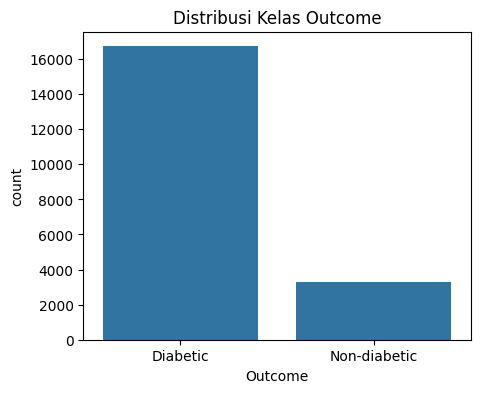

In [ ]:
print(df['Outcome'].value_counts())
print("\nProporsi (%):")
print((df['Outcome'].value_counts(normalize=True) * 100).round(2))

plt.figure(figsize=(5,4))
sns.countplot(data=df, x='Outcome')
plt.title('Distribusi Kelas Outcome')
plt.show()

### **Duplikat dan statistik deskriptif**

In [ ]:
print("Jumlah baris duplikat:", df.duplicated().sum())
display(df.describe().T.round(2))

Jumlah baris duplikat: 0


,count,mean,std,min,25%,50%,75%,max
Age,20000.0,49.57,17.32,20.0,35.00,50.00,64.00,79.0
Glucose,20000.0,119.60,29.59,40.0,99.00,120.00,140.00,200.0
Blood Pressure,20000.0,69.43,12.02,30.0,61.00,69.00,78.00,114.0
Skin Thickness,20000.0,20.11,9.13,7.0,13.00,20.00,26.00,57.0
Insulin,20000.0,83.95,53.03,15.0,40.00,79.00,120.00,276.0
BMI,20000.0,32.01,6.91,15.0,27.31,31.99,36.75,50.0
Cholesterol,20000.0,189.56,35.08,100.0,166.00,190.00,213.00,320.0
Diabetes Pedigree Function,20000.0,1.31,0.69,0.1,0.70,1.32,1.91,2.5


### **Nilai 0 pada atribut klinis (nilai tidak valid secara medis)**

In [ ]:
kolom_klinis = [k for k in ['Glucose', 'Blood Pressure', 'Skin Thickness',
                            'Insulin', 'BMI', 'Cholesterol'] if k in df.columns]
print("Jumlah nilai 0 per atribut klinis:")
print((df[kolom_klinis] == 0).sum())

Jumlah nilai 0 per atribut klinis:
Glucose           0
Blood Pressure    0
Skin Thickness    0
Insulin           0
BMI               0
Cholesterol       0
dtype: int64


### **Isi kategori pada atribut kategorikal**

In [ ]:
# Seluruh kolom selain target dipakai sebagai fitur; tipenya dideteksi otomatis
KOLOM_TARGET = ['Outcome', 'Target']
kolom_fitur = [k for k in df.columns if k not in KOLOM_TARGET]

kolom_kategori, kolom_numerik = [], []
for k in kolom_fitur:
    if (not pd.api.types.is_numeric_dtype(df[k])) or pd.api.types.is_bool_dtype(df[k]) or df[k].nunique(dropna=True) <= 2:
        kolom_kategori.append(k)
    else:
        kolom_numerik.append(k)

print("Jumlah fitur :", len(kolom_fitur))
print("Numerik      :", kolom_numerik)
print("Kategorikal  :", kolom_kategori)

for kol in kolom_kategori:
    print(f"\n=== {kol} ===")
    print(df[kol].value_counts(dropna=False))

Jumlah fitur : 14
Numerik      : ['Age', 'Glucose', 'Blood Pressure', 'Skin Thickness', 'Insulin', 'BMI', 'Cholesterol', 'Diabetes Pedigree Function']
Kategorikal  : ['Gender', 'Physical Activity', 'Smoking Status', 'Alcohol Intake', 'Family History', 'Hypertension']

=== Gender ===
Gender
Male      10028
Female     9972
Name: count, dtype: int64

=== Physical Activity ===
Physical Activity
Moderate    9976
Low         5995
High        4029
Name: count, dtype: int64

=== Smoking Status ===
Smoking Status
Never      11999
Former      4968
Current     3033
Name: count, dtype: int64

=== Alcohol Intake ===
Alcohol Intake
None          9925
Occasional    6014
Regular       4061
Name: count, dtype: int64

=== Family History ===
Family History
No     12083
Yes     7917
Name: count, dtype: int64

=== Hypertension ===
Hypertension
No     13974
Yes     6026
Name: count, dtype: int64


### **Ubah target menjadi angka dan hitung baseline**

In [ ]:
df['Target'] = (df['Outcome'] == 'Diabetic').astype(int)   # Diabetic = 1, Non-diabetic = 0
print(df['Target'].value_counts())

baseline = df['Target'].value_counts(normalize=True).max()
print(f"\nAkurasi baseline (menebak kelas mayoritas): {baseline:.4f}")

Target
1    16726
0     3274
Name: count, dtype: int64

Akurasi baseline (menebak kelas mayoritas): 0.8363


### **Distribusi atribut numerik per kelas**

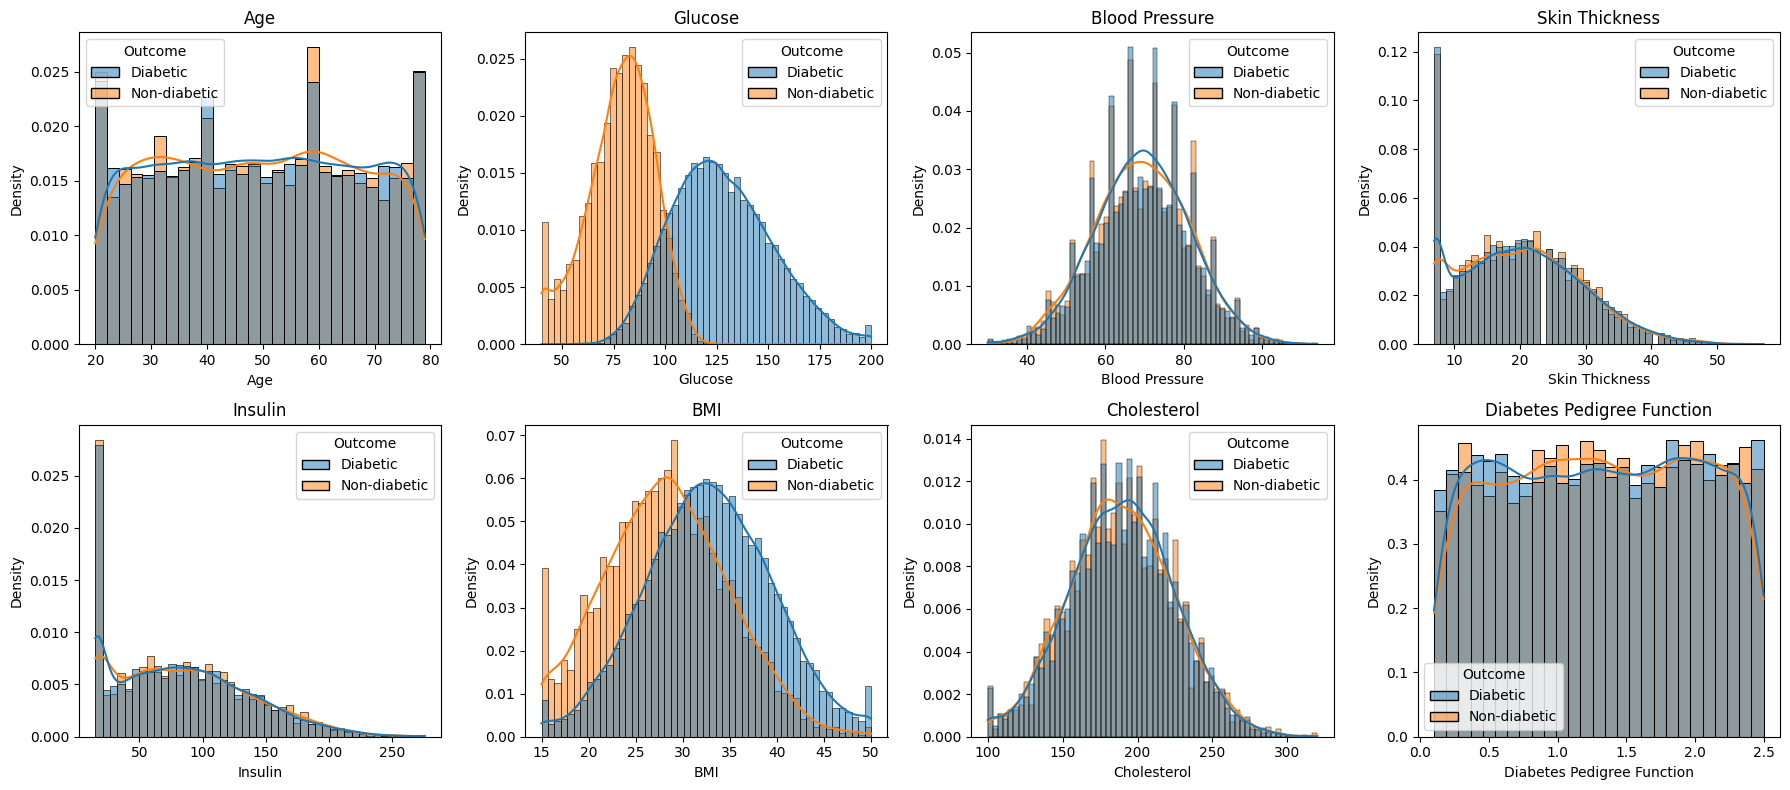

In [ ]:
n = len(kolom_numerik)
kolom_grid = 4
baris_grid = int(np.ceil(n / kolom_grid))
fig, axes = plt.subplots(baris_grid, kolom_grid, figsize=(18, 4 * baris_grid))
axes = np.array(axes).ravel()
for ax, kol in zip(axes, kolom_numerik):
    sns.histplot(data=df, x=kol, hue='Outcome', kde=True,
                 stat='density', common_norm=False, ax=ax)
    ax.set_title(kol)
for ax in axes[n:]:
    ax.axis('off')
plt.tight_layout()
plt.show()

### **Boxplot atribut numerik per kelas (cek pencilan)**

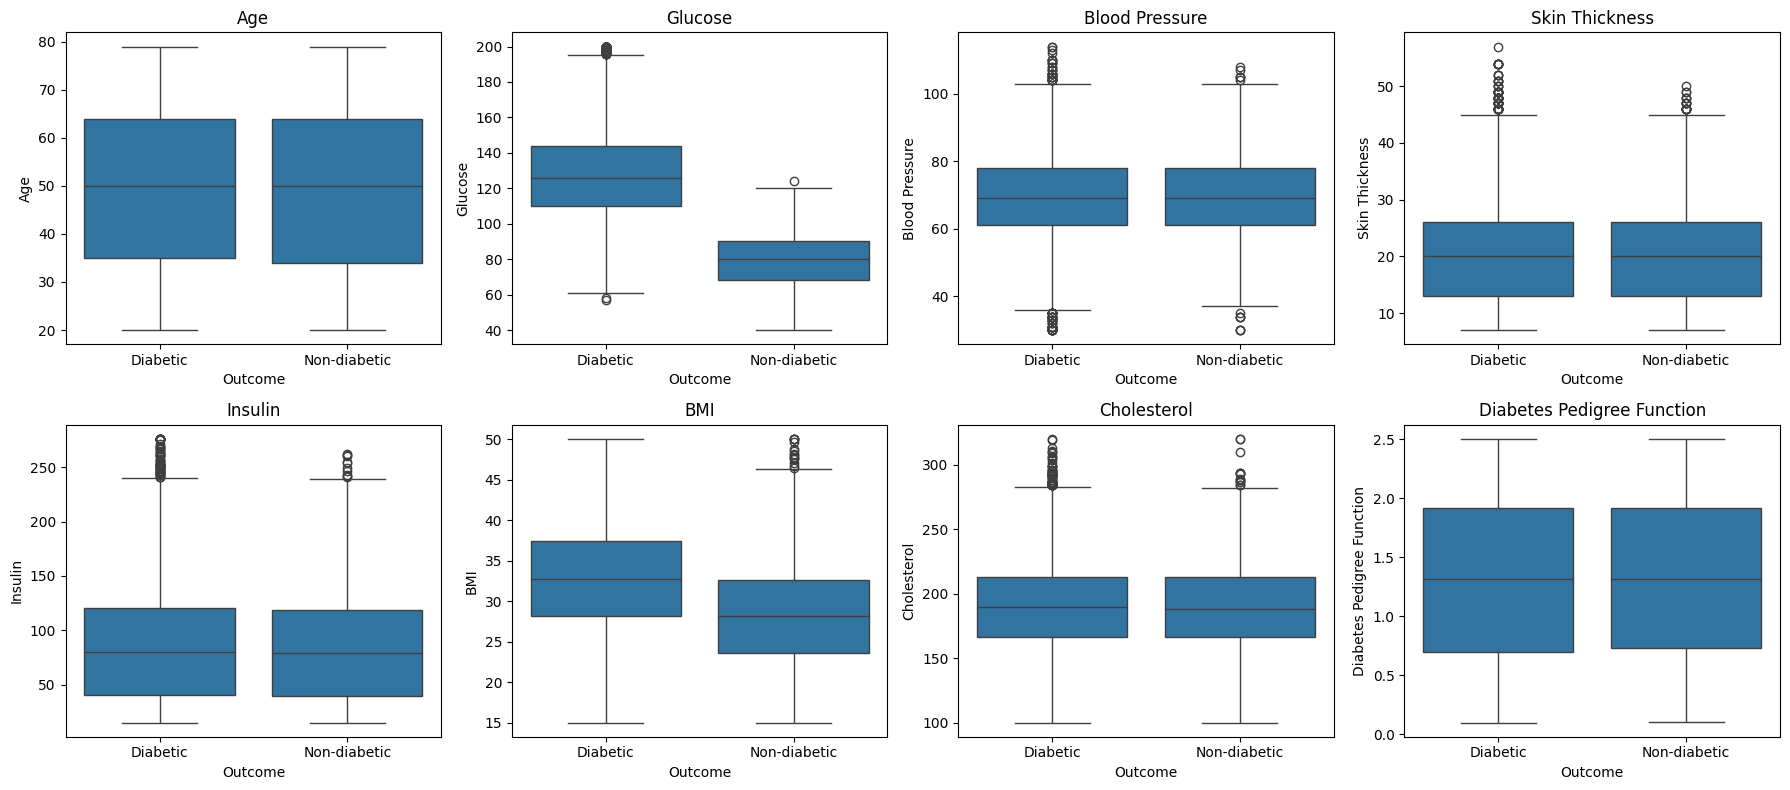

In [ ]:
n = len(kolom_numerik)
kolom_grid = 4
baris_grid = int(np.ceil(n / kolom_grid))
fig, axes = plt.subplots(baris_grid, kolom_grid, figsize=(18, 4 * baris_grid))
axes = np.array(axes).ravel()
for ax, kol in zip(axes, kolom_numerik):
    sns.boxplot(data=df, x='Outcome', y=kol, ax=ax)
    ax.set_title(kol)
for ax in axes[n:]:
    ax.axis('off')
plt.tight_layout()
plt.show()

### **Korelasi atribut numerik dengan target**

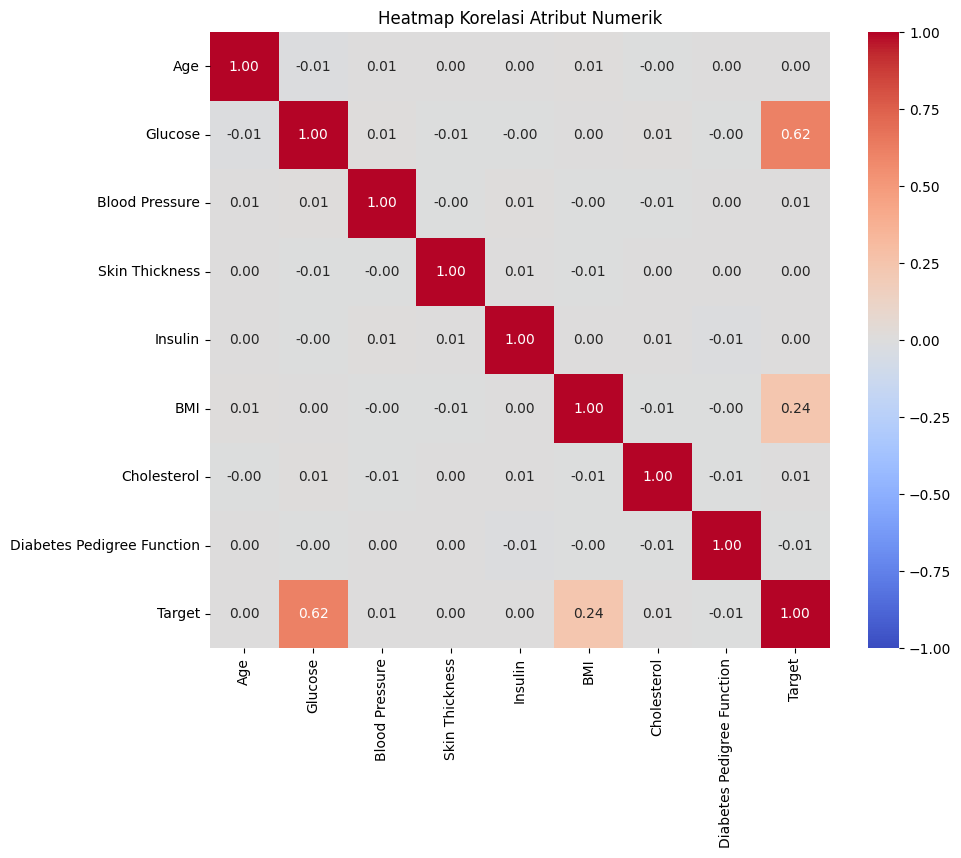

Korelasi dengan Target (diurutkan berdasarkan kekuatan):
Glucose                       0.616
BMI                           0.241
Cholesterol                   0.008
Blood Pressure                0.007
Diabetes Pedigree Function   -0.005
Skin Thickness                0.003
Age                           0.002
Insulin                       0.001
Name: Target, dtype: float64


In [ ]:
corr = df[kolom_numerik + ['Target']].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Heatmap Korelasi Atribut Numerik')
plt.show()

print("Korelasi dengan Target (diurutkan berdasarkan kekuatan):")
print(corr['Target'].drop('Target').sort_values(key=abs, ascending=False).round(3))

### **Proporsi kelas pada setiap kategori**

In [ ]:
for kol in kolom_kategori:
    tab = pd.crosstab(df[kol], df['Outcome'], normalize='index') * 100
    print(f"\n=== {kol} (% Diabetic vs Non-diabetic per kategori) ===")
    print(tab.round(2))


=== Gender (% Diabetic vs Non-diabetic per kategori) ===
Outcome  Diabetic  Non-diabetic
Gender                         
Female      83.95         16.05
Male        83.32         16.68

=== Physical Activity (% Diabetic vs Non-diabetic per kategori) ===
Outcome            Diabetic  Non-diabetic
Physical Activity                        
High                  83.32         16.68
Low                   83.10         16.90
Moderate              84.07         15.93

=== Smoking Status (% Diabetic vs Non-diabetic per kategori) ===
Outcome         Diabetic  Non-diabetic
Smoking Status                        
Current            84.60         15.40
Former             83.21         16.79
Never              83.56         16.44

=== Alcohol Intake (% Diabetic vs Non-diabetic per kategori) ===
Outcome         Diabetic  Non-diabetic
Alcohol Intake                        
None               83.79         16.21
Occasional         83.31         16.69
Regular            83.72         16.28

=== Family H

### **Rentang Glucose dan BMI per kelas**

In [ ]:
print(df.groupby('Outcome')[['Glucose', 'BMI']].describe().T.round(2))

Outcome        Diabetic  Non-diabetic
Glucose count  16726.00       3274.00
        mean     127.67         78.38
        std       24.47         16.07
        min       57.00         40.00
        25%      110.00         68.00
        50%      126.00         80.00
        75%      144.00         90.00
        max      200.00        124.00
BMI     count  16726.00       3274.00
        mean      32.75         28.25
        std        6.73          6.58
        min       15.00         15.00
        25%       28.15         23.55
        50%       32.71         28.12
        75%       37.38         32.65
        max       50.00         50.00


### **Uji pohon keputusan dangkal hanya dengan Glucose dan BMI**

In [ ]:
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.model_selection import StratifiedKFold, cross_val_score

X_gb = df[['Glucose', 'BMI']]
y = df['Target']
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

print("Akurasi pohon keputusan (hanya Glucose + BMI):")
for d in [1, 2, 3, 4]:
    tree = DecisionTreeClassifier(max_depth=d, random_state=RANDOM_STATE)
    acc = cross_val_score(tree, X_gb, y, cv=skf, scoring='accuracy')
    print(f"  max_depth={d}: {acc.mean():.4f} ± {acc.std():.4f}")

tree = DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE).fit(X_gb, y)
print("\nAturan yang ditemukan pohon (depth 3):")
print(export_text(tree, feature_names=['Glucose', 'BMI']))

Akurasi pohon keputusan (hanya Glucose + BMI):
  max_depth=1: 0.9191 ± 0.0036
  max_depth=2: 0.9253 ± 0.0022
  max_depth=3: 0.9618 ± 0.0009
  max_depth=4: 0.9667 ± 0.0008

Aturan yang ditemukan pohon (depth 3):
|--- Glucose <= 91.50
|   |--- BMI <= 33.59
|   |   |--- Glucose <= 84.50
|   |   |   |--- class: 0
|   |   |--- Glucose >  84.50
|   |   |   |--- class: 0
|   |--- BMI >  33.59
|   |   |--- Glucose <= 77.50
|   |   |   |--- class: 0
|   |   |--- Glucose >  77.50
|   |   |   |--- class: 1
|--- Glucose >  91.50
|   |--- Glucose <= 101.50
|   |   |--- BMI <= 26.94
|   |   |   |--- class: 0
|   |   |--- BMI >  26.94
|   |   |   |--- class: 1
|   |--- Glucose >  101.50
|   |   |--- BMI <= 21.81
|   |   |   |--- class: 1
|   |   |--- BMI >  21.81
|   |   |   |--- class: 1



### **Bandingkan dengan semua atribut**

In [ ]:
X_all = pd.get_dummies(df.drop(columns=['Outcome', 'Target']), drop_first=True)
X_all = X_all.fillna(X_all.median())
tree_all = DecisionTreeClassifier(random_state=RANDOM_STATE)
acc_all = cross_val_score(tree_all, X_all, y, cv=skf, scoring='accuracy')
print(f"Akurasi pohon keputusan (semua atribut): {acc_all.mean():.4f} ± {acc_all.std():.4f}")

Akurasi pohon keputusan (semua atribut): 0.9677 ± 0.0012


## **Tahap 3: Pembersihan data awal**

Sesuai alur penelitian: (1) hapus baris duplikat, (2) ubah nilai 0 yang tidak valid secara medis pada atribut klinis menjadi nilai kosong (NaN). Nilai kosong tersebut diisi (imputasi) di dalam pipeline pra-pemrosesan pada Tahap 4, hanya dari data latih, sehingga tidak ada kebocoran data ke data uji.

In [ ]:
n_awal = len(df)

# 1) Hapus baris duplikat
df = df.drop_duplicates().reset_index(drop=True)
print(f"Baris duplikat dihapus : {n_awal - len(df)}  (sisa {len(df)} baris)")

# 2) Nilai tidak valid: 0 pada atribut klinis -> NaN
jumlah_nol = (df[kolom_klinis] == 0).sum()
df[kolom_klinis] = df[kolom_klinis].replace(0, np.nan)
print("\nNilai 0 yang diubah menjadi NaN per atribut klinis:")
print(jumlah_nol)
print("\nNilai kosong per kolom setelah pembersihan:")
print(df.isnull().sum()[lambda s: s > 0])

print("\nProporsi kelas setelah pembersihan:")
print(df['Target'].value_counts(normalize=True).round(4))

Baris duplikat dihapus : 0  (sisa 20000 baris)

Nilai 0 yang diubah menjadi NaN per atribut klinis:
Glucose           0
Blood Pressure    0
Skin Thickness    0
Insulin           0
BMI               0
Cholesterol       0
dtype: int64

Nilai kosong per kolom setelah pembersihan:
Series([], dtype: int64)

Proporsi kelas setelah pembersihan:
Target
1    0.8363
0    0.1637
Name: proportion, dtype: float64


## **Tahap 4: Pipeline pra-pemrosesan dan pemodelan (SVM, Random Forest, XGBoost, CatBoost)**

### **Persiapan model dan fungsi evaluasi**

In [ ]:
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score)
from xgboost import XGBClassifier
from catboost import CatBoostClassifier

# Semua kolom fitur dipakai (seluruh kolom selain Outcome dan Target)
X = df[kolom_fitur].copy()
X[kolom_kategori] = X[kolom_kategori].astype(str).replace('nan', 'Missing')   # CatBoost butuh string
y = df['Target']

def onehot():
    return OneHotEncoder(handle_unknown='ignore')

# Imputasi dimasukkan ke pipeline (dipelajari hanya dari data latih, tanpa kebocoran)
num_svm = Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler())])
num_pohon = SimpleImputer(strategy='median')
kat_pipe = Pipeline([('imp', SimpleImputer(strategy='most_frequent')), ('oh', onehot())])

# SVM: imputasi + standardisasi + one-hot | RF dan XGBoost: imputasi + one-hot
pra_svm = ColumnTransformer([('num', num_svm, kolom_numerik),
                             ('kat', kat_pipe, kolom_kategori)])
pra_pohon = ColumnTransformer([('num', num_pohon, kolom_numerik),
                               ('kat', kat_pipe, kolom_kategori)])
kolom_gb = [k for k in ['Glucose', 'BMI'] if k in kolom_numerik]
pra_gb = ColumnTransformer([('num', num_svm, kolom_gb)])

def buat_model():
    return {
        'Acuan: tebak mayoritas': DummyClassifier(strategy='most_frequent'),
        'Acuan: LogReg (Glucose+BMI)': Pipeline([('pra', pra_gb),
                                                 ('model', LogisticRegression(max_iter=1000))]),
        'SVM': Pipeline([('pra', pra_svm), ('model', SVC(random_state=RANDOM_STATE))]),
        'Random Forest': Pipeline([('pra', pra_pohon),
                                   ('model', RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1))]),
        'XGBoost': Pipeline([('pra', pra_pohon),
                             ('model', XGBClassifier(random_state=RANDOM_STATE, n_jobs=-1))]),
        'CatBoost': CatBoostClassifier(random_seed=RANDOM_STATE, verbose=0),
    }

def latih(model, X_latih, y_latih):
    # CatBoost menerima atribut kategorikal secara langsung
    if isinstance(model, CatBoostClassifier):
        model.fit(X_latih, y_latih, cat_features=kolom_kategori)
    else:
        model.fit(X_latih, y_latih)
    return model

def skor_kontinu(model, X_uji):
    if hasattr(model, 'predict_proba'):
        return model.predict_proba(X_uji)[:, 1]
    return model.decision_function(X_uji)

def hitung_metrik(y_benar, y_pred, y_skor):
    return {'Akurasi': accuracy_score(y_benar, y_pred),
            'Presisi': precision_score(y_benar, y_pred, zero_division=0),
            'Recall': recall_score(y_benar, y_pred),
            'F1': f1_score(y_benar, y_pred),
            'AUC-ROC': roc_auc_score(y_benar, y_skor),
            'F1-makro': f1_score(y_benar, y_pred, average='macro')}

print("Jumlah data (baris, kolom fitur):", X.shape, "| Proporsi Diabetic:", round(y.mean(), 4))

Jumlah data (baris, kolom fitur): (20000, 14) | Proporsi Diabetic: 0.8363


### **Skema 1, tanpa Stratified K-Fold (hold-out 80:20)**

In [ ]:
X_latih, X_uji, y_latih, y_uji = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)
print("Data latih:", X_latih.shape[0], "| Data uji:", X_uji.shape[0])
print("Proporsi Diabetic latih:", round(y_latih.mean(), 4), "| uji:", round(y_uji.mean(), 4))

baris = {}
for nama, model in buat_model().items():
    latih(model, X_latih, y_latih)
    baris[nama] = hitung_metrik(y_uji, model.predict(X_uji), skor_kontinu(model, X_uji))

hasil_holdout = pd.DataFrame(baris).T
display(hasil_holdout.round(4))

Data latih: 16000 | Data uji: 4000
Proporsi Diabetic latih: 0.8363 | uji: 0.8362


,Akurasi,Presisi,Recall,F1,AUC-ROC,F1-makro
Acuan: tebak mayoritas,0.8362,0.8362,1.0000,0.9108,0.5000,0.4554
Acuan: LogReg (Glucose+BMI),0.9760,0.9831,0.9883,0.9857,0.9972,0.9557
SVM,0.9752,0.9813,0.9892,0.9853,0.9964,0.9540
Random Forest,0.9732,0.9784,0.9898,0.9841,0.9953,0.9500
XGBoost,0.9745,0.9827,0.9868,0.9848,0.9965,0.9530
CatBoost,0.9768,0.9848,0.9874,0.9861,0.9968,0.9573


### **Skema 2, Stratified 10-Fold Cross Validation**

In [ ]:
skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)

per_fold = {}
for nama in buat_model():
    catatan_fold = []
    for i, (idx_latih, idx_val) in enumerate(skf.split(X, y), start=1):
        model = latih(buat_model()[nama], X.iloc[idx_latih], y.iloc[idx_latih])
        X_val, y_val = X.iloc[idx_val], y.iloc[idx_val]
        m = hitung_metrik(y_val, model.predict(X_val), skor_kontinu(model, X_val))
        catatan_fold.append({'Fold': i, **m})
    per_fold[nama] = pd.DataFrame(catatan_fold).set_index('Fold')

hasil_cv_rata = pd.DataFrame({n: t.mean() for n, t in per_fold.items()}).T
hasil_cv_sd = pd.DataFrame({n: t.std(ddof=1) for n, t in per_fold.items()}).T

print("=== Rata-rata ± SD (10 fold) ===")
display(hasil_cv_rata.round(4).astype(str) + ' ± ' + hasil_cv_sd.round(4).astype(str))

print("\n=== Selisih hold-out dikurangi rata-rata 10-fold ===")
display((hasil_holdout - hasil_cv_rata).round(4))

=== Rata-rata ± SD (10 fold) ===


,Akurasi,Presisi,Recall,F1,AUC-ROC,F1-makro
Acuan: tebak mayoritas,0.8363 ± 0.0003,0.8363 ± 0.0003,1.0 ± 0.0,0.9109 ± 0.0002,0.5 ± 0.0,0.4554 ± 0.0001
Acuan: LogReg (Glucose+BMI),0.9782 ± 0.0032,0.9856 ± 0.0025,0.9883 ± 0.002,0.987 ± 0.0019,0.9972 ± 0.0005,0.9599 ± 0.006
SVM,0.9759 ± 0.0036,0.9823 ± 0.0032,0.989 ± 0.0023,0.9856 ± 0.0021,0.9964 ± 0.0006,0.9553 ± 0.0067
Random Forest,0.9734 ± 0.0031,0.9792 ± 0.0026,0.9892 ± 0.0015,0.9842 ± 0.0018,0.9954 ± 0.001,0.9504 ± 0.0059
XGBoost,0.9753 ± 0.0023,0.9842 ± 0.0018,0.9862 ± 0.0021,0.9852 ± 0.0014,0.9963 ± 0.0006,0.9546 ± 0.0042
CatBoost,0.9758 ± 0.003,0.9846 ± 0.0023,0.9866 ± 0.0019,0.9856 ± 0.0018,0.9967 ± 0.0006,0.9557 ± 0.0055



=== Selisih hold-out dikurangi rata-rata 10-fold ===


,Akurasi,Presisi,Recall,F1,AUC-ROC,F1-makro
Acuan: tebak mayoritas,-0.0000,-0.0000,0.0000,-0.0000,0.0000,-0.0000
Acuan: LogReg (Glucose+BMI),-0.0022,-0.0025,-0.0000,-0.0013,-0.0001,-0.0042
SVM,-0.0006,-0.0010,0.0002,-0.0004,-0.0000,-0.0013
Random Forest,-0.0002,-0.0007,0.0006,-0.0001,-0.0001,-0.0004
XGBoost,-0.0008,-0.0015,0.0006,-0.0004,0.0002,-0.0016
CatBoost,0.0009,0.0002,0.0008,0.0005,0.0001,0.0016


### **Uji kestabilan hold-out dengan 10 pembagian berbeda**

In [ ]:
daftar_seed = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
catatan = []
for seed in daftar_seed:
    Xl, Xu, yl, yu = train_test_split(X, y, test_size=0.20, stratify=y, random_state=seed)
    for nama, model in buat_model().items():
        if nama.startswith('Acuan'):
            continue
        latih(model, Xl, yl)
        pred = model.predict(Xu)
        catatan.append({'Seed': seed, 'Model': nama,
                        'Akurasi': accuracy_score(yu, pred),
                        'F1-makro': f1_score(yu, pred, average='macro')})

ulang = pd.DataFrame(catatan)
ringkas = ulang.groupby('Model')['Akurasi'].agg(['min', 'max', 'mean', 'std'])
ringkas['rentang'] = ringkas['max'] - ringkas['min']
print("=== Akurasi hold-out pada 10 pembagian data berbeda ===")
display(ringkas.round(4))

peringkat = ulang.pivot(index='Seed', columns='Model', values='Akurasi').rank(axis=1, ascending=False)
print("\nBerapa kali tiap model menjadi peringkat 1 (dari 10 pembagian):")
print((peringkat == 1).sum())

=== Akurasi hold-out pada 10 pembagian data berbeda ===


,min,max,mean,std,rentang
Model,,,,,
CatBoost,0.9732,0.9795,0.9764,0.0018,0.0063
Random Forest,0.9688,0.9740,0.9721,0.0016,0.0052
SVM,0.9725,0.9755,0.9739,0.0012,0.0030
XGBoost,0.9732,0.9768,0.9754,0.0013,0.0035



Berapa kali tiap model menjadi peringkat 1 (dari 10 pembagian):
Model
CatBoost         7
Random Forest    0
SVM              1
XGBoost          1
dtype: int64


## **Tahap 5: Perbandingan kinerja model**

Hasil dua skema (hold-out 80:20 dan Stratified 10-Fold) dibandingkan untuk keempat algoritma pada metrik Accuracy, Precision, Recall, F1 Score, dan AUC-ROC, lalu diuji apakah perbedaan antar algoritma signifikan.

Hold-out 80:20                                  \
                     Akurasi Presisi  Recall      F1 AUC-ROC   
SVM                   0.9752  0.9813  0.9892  0.9853  0.9964   
Random Forest         0.9732  0.9784  0.9898  0.9841  0.9953   
XGBoost               0.9745  0.9827  0.9868  0.9848  0.9965   
CatBoost              0.9768  0.9848  0.9874  0.9861  0.9968   

              Stratified 10-Fold (rata-rata)                                  
                                     Akurasi Presisi  Recall      F1 AUC-ROC  
SVM                                   0.9759  0.9823  0.9890  0.9856  0.9964  
Random Forest                         0.9734  0.9792  0.9892  0.9842  0.9954  
XGBoost                               0.9753  0.9842  0.9862  0.9852  0.9963  
CatBoost                              0.9758  0.9846  0.9866  0.9856  0.9967

Acuan (pembanding, bukan kandidat model):


Hold-out         10-Fold        
                             Akurasi      F1 Akurasi      F1
Acuan: tebak mayoritas        0.8362  0.9108  0.8363  0.9109
Acuan: LogReg (Glucose+BMI)   0.9760  0.9857  0.9782  0.9870

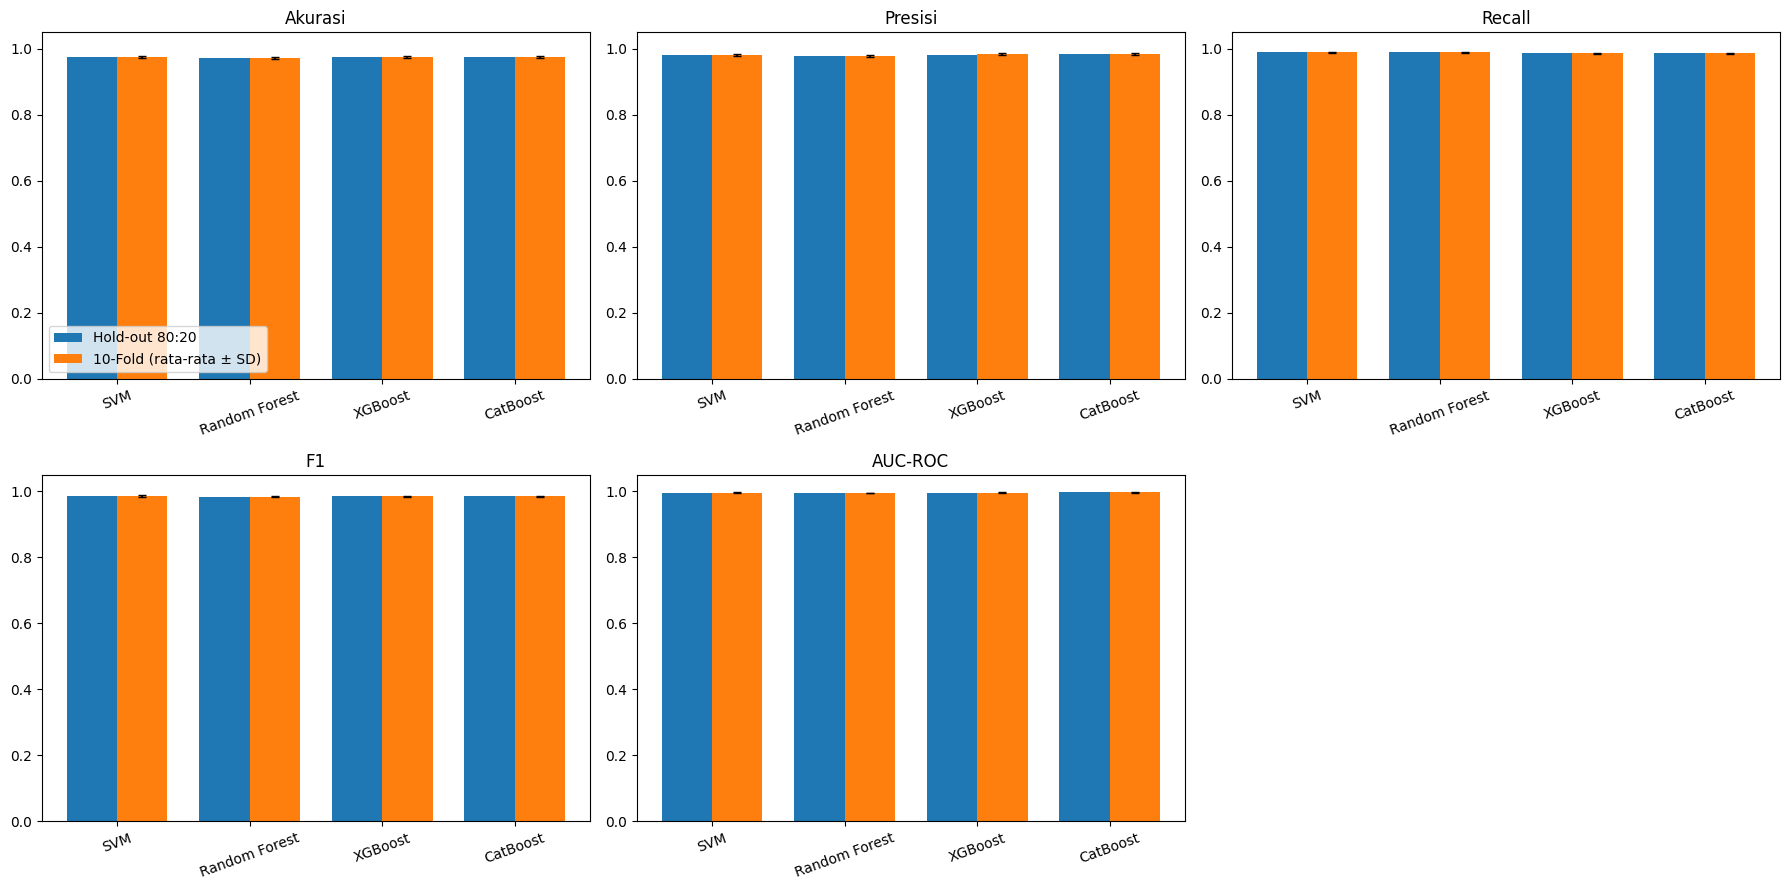

In [ ]:
metrik_utama = ['Akurasi', 'Presisi', 'Recall', 'F1', 'AUC-ROC']
model_utama = [n for n in hasil_holdout.index if not n.startswith('Acuan')]

perbandingan = pd.concat({
    'Hold-out 80:20': hasil_holdout.loc[model_utama, metrik_utama],
    'Stratified 10-Fold (rata-rata)': hasil_cv_rata.loc[model_utama, metrik_utama],
}, axis=1)
display(perbandingan.round(4))

print("Acuan (pembanding, bukan kandidat model):")
display(pd.concat({'Hold-out': hasil_holdout.loc[[n for n in hasil_holdout.index if n.startswith('Acuan')], ['Akurasi', 'F1']],
                   '10-Fold': hasil_cv_rata.loc[[n for n in hasil_cv_rata.index if n.startswith('Acuan')], ['Akurasi', 'F1']]}, axis=1).round(4))

# Grafik: hold-out vs rata-rata 10-fold untuk setiap metrik
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
axes = axes.ravel()
lebar = 0.38
pos = np.arange(len(model_utama))
for ax, m in zip(axes, metrik_utama):
    ax.bar(pos - lebar/2, hasil_holdout.loc[model_utama, m], lebar, label='Hold-out 80:20')
    ax.bar(pos + lebar/2, hasil_cv_rata.loc[model_utama, m], lebar,
           yerr=hasil_cv_sd.loc[model_utama, m], capsize=3, label='10-Fold (rata-rata ± SD)')
    ax.set_xticks(pos)
    ax.set_xticklabels(model_utama, rotation=20)
    ax.set_title(m)
    ax.set_ylim(0, 1.05)
axes[0].legend()
axes[-1].axis('off')
plt.tight_layout()
plt.show()

### **Uji perbedaan antar algoritma (Stratified 10-Fold)**

Rumusan masalah 2 menanyakan *apakah* ada perbedaan metrik antar algoritma, sehingga perlu uji statistik, bukan hanya membandingkan rata-rata. Karena keempat model dievaluasi pada fold yang sama (data berpasangan), dipakai **uji Friedman** per metrik. Bila signifikan, dilanjutkan **uji Wilcoxon berpasangan dengan koreksi Holm**.

Catatan: antar fold, data latihnya saling tumpang tindih, sehingga nilai p bersifat pendekatan (cenderung terlalu optimis). Baca bersama besar selisih rata-rata, bukan p-value saja.

In [ ]:
from scipy import stats
from itertools import combinations

metrik_uji = ['Akurasi', 'Presisi', 'Recall', 'F1', 'AUC-ROC']
# baris = fold, kolom = model
nilai_fold = {m: pd.DataFrame({n: per_fold[n][m] for n in model_utama}) for m in metrik_uji}

# 1) Uji Friedman per metrik
baris_friedman = []
for m in metrik_uji:
    chi2, p = stats.friedmanchisquare(*[nilai_fold[m][n] for n in model_utama])
    baris_friedman.append({'Metrik': m, 'Chi2 Friedman': chi2, 'p-value': p,
                           'Beda signifikan (α=0.05)': 'Ya' if p < 0.05 else 'Tidak'})
hasil_friedman = pd.DataFrame(baris_friedman).set_index('Metrik')
print("=== Uji Friedman (antar 4 algoritma, 10 fold) ===")
display(hasil_friedman.round(4))

# 2) Uji lanjut Wilcoxon berpasangan + koreksi Holm
def koreksi_holm(pvals):
    pvals = np.asarray(pvals, dtype=float)
    urut = np.argsort(pvals)
    hasil, maks = np.empty(len(pvals)), 0.0
    for r, i in enumerate(urut):
        maks = max(maks, min(1.0, (len(pvals) - r) * pvals[i]))
        hasil[i] = maks
    return hasil

baris_pasangan = []
for m in metrik_uji:
    pasangan = list(combinations(model_utama, 2))
    p_mentah = []
    for a, b in pasangan:
        try:
            p_mentah.append(stats.wilcoxon(nilai_fold[m][a], nilai_fold[m][b]).pvalue)
        except ValueError:      # selisih seluruhnya nol
            p_mentah.append(1.0)
    p_holm = koreksi_holm(p_mentah)
    for (a, b), pm, ph in zip(pasangan, p_mentah, p_holm):
        baris_pasangan.append({'Metrik': m, 'Model A': a, 'Model B': b,
                               'Selisih rata-rata (A-B)': nilai_fold[m][a].mean() - nilai_fold[m][b].mean(),
                               'p-value': pm, 'p-Holm': ph})
pasangan_df = pd.DataFrame(baris_pasangan)
signifikan = pasangan_df[pasangan_df['p-Holm'] < 0.05]

print("\n=== Pasangan algoritma yang berbeda signifikan (Wilcoxon, p-Holm < 0.05) ===")
if len(signifikan):
    display(signifikan.set_index(['Metrik', 'Model A', 'Model B']).round(4))
else:
    print("Tidak ada pasangan algoritma yang berbeda signifikan.")

=== Uji Friedman (antar 4 algoritma, 10 fold) ===


,Chi2 Friedman,p-value,Beda signifikan (α=0.05)
Metrik,,,
Akurasi,8.7526,0.0328,Ya
Presisi,19.6800,0.0002,Ya
Recall,12.0330,0.0073,Ya
F1,6.9600,0.0732,Tidak
AUC-ROC,18.0000,0.0004,Ya



=== Pasangan algoritma yang berbeda signifikan (Wilcoxon, p-Holm < 0.05) ===


Selisih rata-rata (A-B)  p-value  p-Holm
Metrik  Model A       Model B                                                
Akurasi Random Forest CatBoost                       -0.0024   0.0039  0.0234
Presisi SVM           Random Forest                   0.0031   0.0059  0.0234
        Random Forest XGBoost                        -0.0050   0.0020  0.0117
                      CatBoost                       -0.0054   0.0020  0.0117
Recall  Random Forest XGBoost                         0.0030   0.0078  0.0391
                      CatBoost                        0.0026   0.0039  0.0234
F1      Random Forest CatBoost                       -0.0014   0.0039  0.0234
AUC-ROC SVM           Random Forest                   0.0010   0.0059  0.0293
        Random Forest XGBoost                        -0.0009   0.0098  0.0391
                      CatBoost                       -0.0014   0.0020  0.0117
        XGBoost       CatBoost                       -0.0005   0.0098  0.0391

## **Tahap 6: Model terbaik dan kesimpulan**

Model terbaik ditentukan dari hasil Stratified 10-Fold pada kelima metrik (akurasi, presisi, recall, F1-score, AUC-ROC): peringkat tiap model dihitung per metrik, lalu dirata-ratakan. Bila seri, dipakai F1.

In [ ]:
# Peringkat per metrik (1 = terbaik) berdasarkan rata-rata 10-Fold
peringkat_metrik = pd.DataFrame({m: hasil_cv_rata.loc[model_utama, m].rank(ascending=False, method='min')
                                 for m in metrik_utama})
peringkat_metrik['Rata-rata peringkat'] = peringkat_metrik.mean(axis=1)
peringkat_metrik['F1'] = peringkat_metrik['F1'].astype(float)

print("Model terbaik pada setiap metrik (10-Fold):")
for m in metrik_utama:
    nama_m = hasil_cv_rata.loc[model_utama, m].idxmax()
    print(f"  {m:8s}: {nama_m:14s} ({hasil_cv_rata.loc[nama_m, m]:.4f})")

urutan = peringkat_metrik.assign(F1_rata=hasil_cv_rata.loc[model_utama, 'F1']) \
                         .sort_values(['Rata-rata peringkat', 'F1_rata'], ascending=[True, False])
print("\nPeringkat tiap model (angka kecil = lebih baik):")
display(urutan.drop(columns='F1_rata'))

nama_terbaik = urutan.index[0]
print(f"\nMODEL TERBAIK: {nama_terbaik}")
for m in metrik_utama:
    print(f"  {m:8s}: 10-Fold = {hasil_cv_rata.loc[nama_terbaik, m]:.4f} ± {hasil_cv_sd.loc[nama_terbaik, m]:.4f}"
          f" | Hold-out = {hasil_holdout.loc[nama_terbaik, m]:.4f}")

tidak_sig = [m for m in metrik_utama if hasil_friedman.loc[m, 'p-value'] >= 0.05]
if tidak_sig:
    print("\nCatatan: pada metrik", ", ".join(tidak_sig),
          "perbedaan antar algoritma TIDAK signifikan secara statistik (Friedman, α=0.05);",
          "unggulan pada metrik tersebut sebaiknya tidak disimpulkan sebagai perbedaan nyata.")

Model terbaik pada setiap metrik (10-Fold):
  Akurasi : SVM            (0.9759)
  Presisi : CatBoost       (0.9846)
  Recall  : Random Forest  (0.9892)
  F1      : SVM            (0.9856)
  AUC-ROC : CatBoost       (0.9967)

Peringkat tiap model (angka kecil = lebih baik):


,Akurasi,Presisi,Recall,F1,AUC-ROC,Rata-rata peringkat
SVM,1.0,3.0,2.0,1.0,2.0,1.8
CatBoost,2.0,1.0,3.0,2.0,1.0,1.8
XGBoost,3.0,2.0,4.0,3.0,3.0,3.0
Random Forest,4.0,4.0,1.0,4.0,4.0,3.4



MODEL TERBAIK: SVM
  Akurasi : 10-Fold = 0.9759 ± 0.0036 | Hold-out = 0.9752
  Presisi : 10-Fold = 0.9823 ± 0.0032 | Hold-out = 0.9813
  Recall  : 10-Fold = 0.9890 ± 0.0023 | Hold-out = 0.9892
  F1      : 10-Fold = 0.9856 ± 0.0021 | Hold-out = 0.9853
  AUC-ROC : 10-Fold = 0.9964 ± 0.0006 | Hold-out = 0.9964

Catatan: pada metrik F1 perbedaan antar algoritma TIDAK signifikan secara statistik (Friedman, α=0.05); unggulan pada metrik tersebut sebaiknya tidak disimpulkan sebagai perbedaan nyata.


### **Prediksi dengan seluruh kolom data**

#### **Latih model terbaik pada seluruh data**

Model terbaik dari Tahap 6 dilatih ulang pada seluruh baris dan seluruh kolom fitur.

In [ ]:
model_final = latih(buat_model()[nama_terbaik], X, y)   # seluruh baris dan seluruh kolom fitur
print("Model final :", nama_terbaik)
print("Fitur yang dipakai:", list(X.columns))

Model final : SVM
Fitur yang dipakai: ['Gender', 'Age', 'Physical Activity', 'Smoking Status', 'Alcohol Intake', 'Glucose', 'Blood Pressure', 'Skin Thickness', 'Insulin', 'BMI', 'Cholesterol', 'Diabetes Pedigree Function', 'Family History', 'Hypertension']


#### **Fungsi prediksi untuk data baru**

In [ ]:
def prediksi(df_baru):
    """Prediksi untuk data baru; semua kolom fitur diproses, kolom target (jika ada) diabaikan."""
    D = df_baru.copy()
    kurang = [k for k in kolom_fitur if k not in D.columns]
    if kurang:
        raise ValueError(f"Kolom berikut tidak ada pada data baru: {kurang}")
    D = D[kolom_fitur]                                   # urutan kolom sama dengan data latih
    D[kolom_kategori] = D[kolom_kategori].astype(str).replace('nan', 'Missing')
    pred = model_final.predict(D)
    proba = model_final.predict_proba(D)[:, 1]
    hasil = df_baru.copy()
    hasil['Prediksi'] = np.where(np.ravel(pred) == 1, 'Diabetic', 'Non-diabetic')
    hasil['Probabilitas_Diabetic'] = proba.round(4)
    return hasil

# Contoh: 5 baris pertama dari data
display(prediksi(df.head())[['Outcome', 'Prediksi', 'Probabilitas_Diabetic']])

AttributeError: This 'Pipeline' has no attribute 'predict_proba'

#### **Prediksi dari file CSV baru (opsional)**

In [ ]:
# Jalankan sel ini jika ingin memprediksi file CSV baru
from google.colab import files
unggah_baru = files.upload()
file_baru = list(unggah_baru.keys())[0]
df_baru = pd.read_csv(file_baru, keep_default_na=False, na_values=[''])

hasil_baru = prediksi(df_baru)
display(hasil_baru.head())
hasil_baru.to_csv('hasil_prediksi.csv', index=False)
files.download('hasil_prediksi.csv')